In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Converter ONS para UTC

In [18]:
df_geracao = pd.read_csv('/content/geracao_horaria.csv')

In [19]:
df_geracao['din_instante'] = pd.to_datetime(df_geracao['din_instante'])
df_geracao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   din_instante  8760 non-null   datetime64[ns]
 1   val_geracao   8760 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 137.0 KB


In [20]:
df_geracao.head()

,din_instante,val_geracao
0,2025-01-01 00:00:00,0.0
1,2025-01-01 01:00:00,0.0
2,2025-01-01 02:00:00,0.0
3,2025-01-01 03:00:00,0.0
4,2025-01-01 04:00:00,0.0


In [21]:
df_geracao_utc = df_geracao.copy()

In [22]:
df_geracao_utc['din_instante'] = df_geracao_utc['din_instante'].dt.tz_localize('America/Sao_Paulo').dt.tz_convert('UTC')


In [23]:
df_geracao_utc.head()

,din_instante,val_geracao
0,2025-01-01 03:00:00+00:00,0.0
1,2025-01-01 04:00:00+00:00,0.0
2,2025-01-01 05:00:00+00:00,0.0
3,2025-01-01 06:00:00+00:00,0.0
4,2025-01-01 07:00:00+00:00,0.0


In [24]:
df_geracao_utc['din_instante'] = df_geracao_utc['din_instante'].dt.tz_localize(None)

In [25]:
df_geracao_utc.head()

,din_instante,val_geracao
0,2025-01-01 03:00:00,0.0
1,2025-01-01 04:00:00,0.0
2,2025-01-01 05:00:00,0.0
3,2025-01-01 06:00:00,0.0
4,2025-01-01 07:00:00,0.0


In [26]:
df_geracao_utc.tail()

,din_instante,val_geracao
8755,2025-12-31 22:00:00,0.0
8756,2025-12-31 23:00:00,0.0
8757,2026-01-01 00:00:00,0.0
8758,2026-01-01 01:00:00,0.0
8759,2026-01-01 02:00:00,0.0


In [27]:
df_geracao_utc = df_geracao_utc[df_geracao_utc['din_instante'].dt.year != 2026]

In [28]:
df_geracao_utc.tail()

,din_instante,val_geracao
8752,2025-12-31 19:00:00,28.198
8753,2025-12-31 20:00:00,16.616
8754,2025-12-31 21:00:00,0.645
8755,2025-12-31 22:00:00,0.000
8756,2025-12-31 23:00:00,0.000


In [29]:
novas_linhas = pd.DataFrame({
    'din_instante': ['2025-01-01 00:00:00', '2025-01-01 01:00:00', '2025-01-01 02:00:00'],
    'val_geracao': [0.0, 0.0, 0.0]
})
novas_linhas['din_instante'] = pd.to_datetime(novas_linhas['din_instante'])
df_geracao_utc['din_instante'] = pd.to_datetime(df_geracao_utc['din_instante'])
df_geracao_utc = pd.concat([novas_linhas, df_geracao_utc], ignore_index=True)

In [30]:
print(df_geracao_utc.shape)
print(df_geracao_utc['din_instante'].min())
print(df_geracao_utc['din_instante'].max())
print(df_geracao_utc['din_instante'].duplicated().sum())

print(
    df_geracao_utc['din_instante']
    .diff()
    .value_counts()
)

(8760, 2)
2025-01-01 00:00:00
2025-12-31 23:00:00
0
din_instante
0 days 01:00:00    8759
Name: count, dtype: int64


In [31]:
df_geracao_utc.head()

,din_instante,val_geracao
0,2025-01-01 00:00:00,0.0
1,2025-01-01 01:00:00,0.0
2,2025-01-01 02:00:00,0.0
3,2025-01-01 03:00:00,0.0
4,2025-01-01 04:00:00,0.0


In [32]:
df_geracao_utc.to_csv('geracao_horaria_utc.csv', index=False)

## Dados Meteorológicos

In [33]:
df = pd.read_csv('/content/df_final_2025_tratado.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/df_final_2025.csv'

In [4]:
df.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,26.2,69.0,1.7,965.1,0.0,0.000000
1,2025-01-01 01:00:00,25.1,71.0,2.3,965.7,0.0,0.000000
2,2025-01-01 02:00:00,25.2,70.0,1.7,966.4,0.0,0.016689
3,2025-01-01 03:00:00,25.2,71.0,1.8,966.4,0.0,0.055790
4,2025-01-01 04:00:00,24.4,78.0,1.5,966.1,0.0,0.017643


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 7 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   data_hora_utc                                         8760 non-null   object 
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8749 non-null   float64
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8255 non-null   float64
 3   VENTO, VELOCIDADE HORARIA(m/s)                        4460 non-null   float64
 4   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8751 non-null   float64
 5   Radiação (Wh/m2)                                      8760 non-null   float64
 6   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64
dtypes: float64(6), object(1)
memory usage: 479.2+ KB


In [6]:
df_copy = df.copy()

## Auditoria final e análise exploratória

### Integridade temporal

In [ ]:
df['data_hora_utc'] = pd.to_datetime(df['data_hora_utc'], errors='coerce')
df['data_hora_utc'].dtype

dtype('<M8[ns]')

In [ ]:
datas_invalidas = df['data_hora_utc'].isna().sum()
print(datas_invalidas)

0


In [ ]:
esta_ordenada = df['data_hora_utc'].is_monotonic_increasing
print(esta_ordenada)

True


In [ ]:
duplicados = df['data_hora_utc'].duplicated()
print(duplicados.sum())

0


In [ ]:
inicio = df['data_hora_utc'].min()
fim = df['data_hora_utc'].max()
print(inicio)
print(fim)

2025-01-01 00:00:00
2025-12-31 23:00:00


In [ ]:
# horas esperadas 8760
horas_esperadas = df['data_hora_utc'].nunique()
print(horas_esperadas)

8760


In [ ]:
timeline_esperada = pd.date_range(
    start= df['data_hora_utc'].min(),
    end=df['data_hora_utc'].max(),
    freq='h'
)

In [ ]:
horas_ausentes = timeline_esperada.difference(df['data_hora_utc'])
print(len(horas_ausentes))

0


In [ ]:
df['delta_tempo'] = df['data_hora_utc'].diff()
print(df['delta_tempo'].value_counts().sort_index())

delta_tempo
0 days 01:00:00    8759
Name: count, dtype: int64


In [ ]:
# Todos os registros estão separados por 1h?
frequencia_horaria = (
    df['delta_tempo']
    .dropna()
    .eq(pd.Timedelta(hours=1))
    .all()
)
print(frequencia_horaria)

True


In [ ]:
df = df.drop(columns='delta_tempo', errors='ignore')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 7 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8749 non-null   float64       
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8255 non-null   float64       
 3   VENTO, VELOCIDADE HORARIA(m/s)                        4460 non-null   float64       
 4   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8751 non-null   float64       
 5   Radiação (Wh/m2)                                      8760 non-null   float64       
 6   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 479.2 KB


### Missing values

In [ ]:
df.isna().sum()

,0
data_hora_utc,0
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",11
"UMIDADE RELATIVA DO AR, HORARIA(%)",505
"VENTO, VELOCIDADE HORARIA(m/s)",4300
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",9
Radiação (Wh/m2),0
"PRECIPITACAO ERA5, HORARIA(mm)",0


In [ ]:
df['mes'] = df['data_hora_utc'].dt.to_period('M')
missing_mes = df.groupby('mes').apply(lambda x: x.isna().sum(), include_groups=False)

In [ ]:
print(missing_mes)

         data_hora_utc  TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)  \
mes                                                                   
2025-01              0                                            0   
2025-02              0                                            0   
2025-03              0                                            0   
2025-04              0                                            0   
2025-05              0                                            0   
2025-06              0                                            0   
2025-07              0                                            0   
2025-08              0                                            0   
2025-09              0                                            0   
2025-10              0                                            9   
2025-11              0                                            0   
2025-12              0                                            2   

     

In [ ]:
missing_mes_pct = (
    df.groupby('mes')
      .apply(lambda x: x.isna().mean() * 100, include_groups=False)
      .round(2)
)

display(missing_mes_pct)

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
mes,,,,,,,
2025-01,0.0,0.00,13.17,0.00,0.00,0.0,0.0
2025-02,0.0,0.00,12.05,0.00,0.00,0.0,0.0
2025-03,0.0,0.00,4.70,0.00,0.00,0.0,0.0
2025-04,0.0,0.00,22.08,85.69,0.00,0.0,0.0
2025-05,0.0,0.00,2.02,100.00,0.00,0.0,0.0
2025-06,0.0,0.00,10.42,100.00,0.00,0.0,0.0
2025-07,0.0,0.00,2.82,100.00,0.00,0.0,0.0
2025-08,0.0,0.00,0.54,100.00,0.00,0.0,0.0
2025-09,0.0,0.00,0.83,100.00,0.00,0.0,0.0


In [ ]:
missing_mes_pct.T

mes,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
data_hora_utc,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,1.21,0.0,0.27
"UMIDADE RELATIVA DO AR, HORARIA(%)",13.17,12.05,4.7,22.08,2.02,10.42,2.82,0.54,0.83,1.21,0.0,0.27
"VENTO, VELOCIDADE HORARIA(m/s)",0.00,0.00,0.0,85.69,100.00,100.00,100.00,100.00,100.00,1.21,0.0,0.27
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,1.08,0.0,0.13
Radiação (Wh/m2),0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00
"PRECIPITACAO ERA5, HORARIA(mm)",0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00


In [ ]:
missing_mask = df.drop(
    columns=['data_hora_utc', 'mes'],
    errors='ignore'
).isna()

In [ ]:
df['n_missing'] = missing_mask.sum(axis=1)

In [ ]:
horarios_com_missing = df.loc[
    df['n_missing'] > 0,
    ['data_hora_utc', 'n_missing']
]

display(horarios_com_missing.head(30))

,data_hora_utc,n_missing
9,2025-01-01 09:00:00,1
55,2025-01-03 07:00:00,1
56,2025-01-03 08:00:00,1
57,2025-01-03 09:00:00,1
76,2025-01-04 04:00:00,1
77,2025-01-04 05:00:00,1
78,2025-01-04 06:00:00,1
82,2025-01-04 10:00:00,1
104,2025-01-05 08:00:00,1
105,2025-01-05 09:00:00,1


In [ ]:
df['n_missing'].value_counts().sort_index()

,count
n_missing,
0,4232
1,4251
2,266
3,2
4,9


In [ ]:
variaveis = [
    col for col in df.columns
    if col not in ['data_hora_utc', 'mes', 'n_missing']
]

In [ ]:
for coluna in variaveis:

    mask = df[coluna].isna()

    grupos = mask.ne(mask.shift()).cumsum()

    blocos = (
        df[mask]
        .groupby(grupos[mask])
        .agg(
            inicio=('data_hora_utc', 'min'),
            fim=('data_hora_utc', 'max'),
            quantidade=('data_hora_utc', 'size')
        )
        .sort_values('quantidade', ascending=False)
    )

    print(f'\n--- {coluna} ---')

    if len(blocos) == 0:
        print('Nenhum bloco de missing.')
    else:
        display(blocos.head(20))


--- TEMPERATURA DO AR - BULBO SECO, HORARIA(°C) ---


,inicio,fim,quantidade
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",,,
4,2025-10-22 16:00:00,2025-10-22 22:00:00,7
2,2025-10-14 20:00:00,2025-10-14 20:00:00,1
6,2025-10-27 12:00:00,2025-10-27 12:00:00,1
8,2025-12-02 15:00:00,2025-12-02 15:00:00,1
10,2025-12-23 09:00:00,2025-12-23 09:00:00,1



--- UMIDADE RELATIVA DO AR, HORARIA(%) ---


,inicio,fim,quantidade
"UMIDADE RELATIVA DO AR, HORARIA(%)",,,
156,2025-04-18 06:00:00,2025-04-19 12:00:00,31
162,2025-04-24 18:00:00,2025-04-25 11:00:00,18
202,2025-06-08 19:00:00,2025-06-09 11:00:00,17
18,2025-01-16 22:00:00,2025-01-17 12:00:00,15
174,2025-04-27 22:00:00,2025-04-28 12:00:00,15
64,2025-02-03 22:00:00,2025-02-04 09:00:00,12
196,2025-06-06 01:00:00,2025-06-06 11:00:00,11
152,2025-04-16 02:00:00,2025-04-16 11:00:00,10
172,2025-04-26 22:00:00,2025-04-27 07:00:00,10



--- VENTO, VELOCIDADE HORARIA(m/s) ---


,inicio,fim,quantidade
"VENTO, VELOCIDADE HORARIA(m/s)",,,
2,2025-04-05 07:00:00,2025-09-30 23:00:00,4289
6,2025-10-22 16:00:00,2025-10-22 22:00:00,7
4,2025-10-14 20:00:00,2025-10-14 20:00:00,1
8,2025-10-27 12:00:00,2025-10-27 12:00:00,1
10,2025-12-02 15:00:00,2025-12-02 15:00:00,1
12,2025-12-23 09:00:00,2025-12-23 09:00:00,1



--- PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB) ---


,inicio,fim,quantidade
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",,,
4,2025-10-22 16:00:00,2025-10-22 22:00:00,7
2,2025-10-14 20:00:00,2025-10-14 20:00:00,1
6,2025-12-23 09:00:00,2025-12-23 09:00:00,1



--- Radiação (Wh/m2) ---
Nenhum bloco de missing.

--- PRECIPITACAO ERA5, HORARIA(mm) ---
Nenhum bloco de missing.


In [ ]:
resultado_blocos = []

for coluna in variaveis:

    mask = df[coluna].isna()
    grupos = mask.ne(mask.shift()).cumsum()

    tamanhos = (
        df.loc[mask]
          .groupby(grupos[mask])
          .size()
    )

    maior_bloco = tamanhos.max() if not tamanhos.empty else 0

    resultado_blocos.append({
        'variavel': coluna,
        'maior_bloco_missing_horas': maior_bloco
    })

maiores_blocos = pd.DataFrame(resultado_blocos)

display(
    maiores_blocos.sort_values(
        'maior_bloco_missing_horas',
        ascending=False
    )
)

,variavel,maior_bloco_missing_horas
2,"VENTO, VELOCIDADE HORARIA(m/s)",4289
1,"UMIDADE RELATIVA DO AR, HORARIA(%)",31
0,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",7
3,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",7
4,Radiação (Wh/m2),0
5,"PRECIPITACAO ERA5, HORARIA(mm)",0


In [ ]:
missing_corr = missing_mask.astype(int).corr()

display(missing_corr.round(2))

,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",1.00,0.14,0.04,0.90,NaN,NaN
"UMIDADE RELATIVA DO AR, HORARIA(%)",0.14,1.00,0.03,0.13,NaN,NaN
"VENTO, VELOCIDADE HORARIA(m/s)",0.04,0.03,1.00,0.03,NaN,NaN
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",0.90,0.13,0.03,1.00,NaN,NaN
Radiação (Wh/m2),NaN,NaN,NaN,NaN,NaN,NaN
"PRECIPITACAO ERA5, HORARIA(mm)",NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
missing_simultaneo = (
    missing_mask
    .astype(int)
    .value_counts()
    .reset_index(name='quantidade')
)

display(missing_simultaneo.head(20))

,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)",quantidade
0,0,0,0,0,0,0,4232
1,0,0,1,0,0,0,4023
2,0,1,1,0,0,0,266
3,0,1,0,0,0,0,228
4,1,1,1,1,0,0,9
5,1,1,1,0,0,0,2


In [ ]:
pares_missing = []

for i, col1 in enumerate(variaveis):
    for col2 in variaveis[i + 1:]:

        ambos = (
            df[col1].isna() &
            df[col2].isna()
        ).sum()

        pares_missing.append({
            'variavel_1': col1,
            'variavel_2': col2,
            'missing_simultaneo': ambos
        })

pares_missing = pd.DataFrame(pares_missing)

display(
    pares_missing.sort_values(
        'missing_simultaneo',
        ascending=False
    )
)

,variavel_1,variavel_2,missing_simultaneo
5,"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)",277
1,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","VENTO, VELOCIDADE HORARIA(m/s)",11
0,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)",11
2,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",9
6,"UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",9
9,"VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",9
4,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","PRECIPITACAO ERA5, HORARIA(mm)",0
3,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",Radiação (Wh/m2),0
7,"UMIDADE RELATIVA DO AR, HORARIA(%)",Radiação (Wh/m2),0
8,"UMIDADE RELATIVA DO AR, HORARIA(%)","PRECIPITACAO ERA5, HORARIA(mm)",0


In [ ]:
features = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)',
    'UMIDADE RELATIVA DO AR, HORARIA(%)',
    'VENTO, VELOCIDADE HORARIA(m/s)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)',
    'Radiação (Wh/m2)',
    'PRECIPITACAO ERA5, HORARIA(mm)'
]

In [ ]:
todas_ausentes = df[features].isna().all(axis=1)

print(
    'Horas com todas as features ausentes:',
    todas_ausentes.sum()
)

Horas com todas as features ausentes: 0


In [ ]:
alguma_ausente = df[features].isna().any(axis=1)

print(
    'Horas com pelo menos uma feature ausente:',
    alguma_ausente.sum()
)

Horas com pelo menos uma feature ausente: 4528


In [ ]:
completos = df[features].notna().all(axis=1)

print(
    'Horas com todas as features disponíveis:',
    completos.sum()
)

print(
    'Percentual completamente preenchido:',
    round(completos.mean() * 100, 2),
    '%'
)

Horas com todas as features disponíveis: 4232
Percentual completamente preenchido: 48.31 %


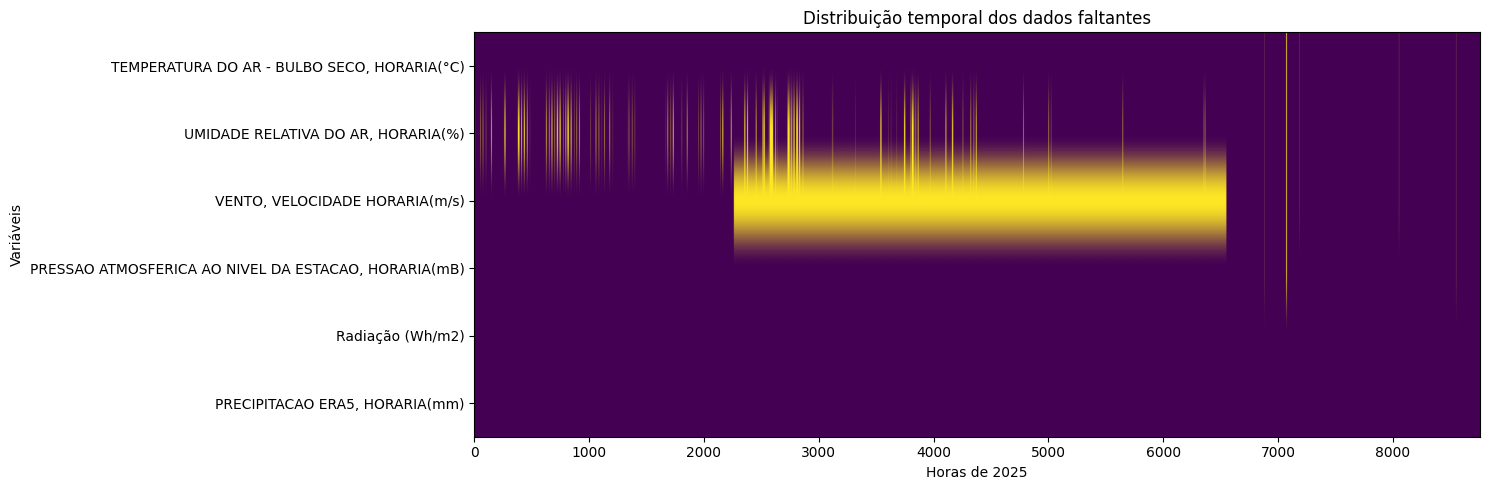

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))

missing_plot = missing_mask.astype(int).T.values

ax.imshow(
    missing_plot,
    aspect='auto'
)

ax.set_yticks(range(len(missing_mask.columns)))
ax.set_yticklabels(missing_mask.columns)

ax.set_xlabel('Horas de 2025')
ax.set_ylabel('Variáveis')
ax.set_title('Distribuição temporal dos dados faltantes')

plt.tight_layout()
plt.show()

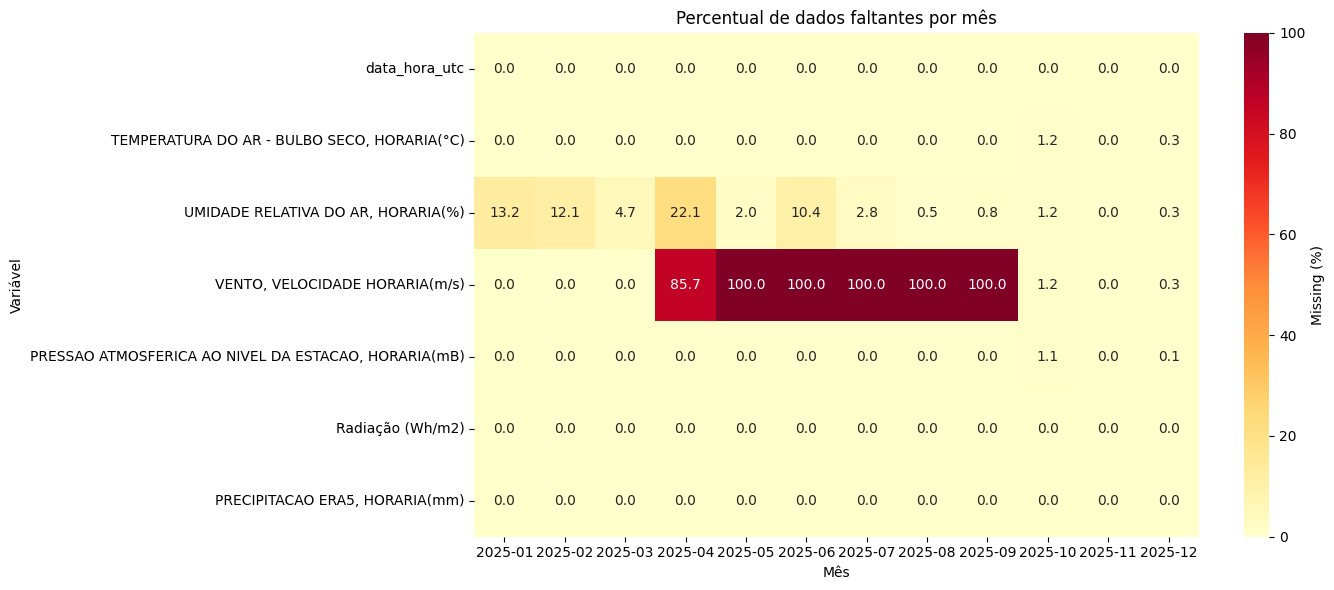

In [ ]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    missing_mes_pct.T,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Missing (%)"}
)

plt.title("Percentual de dados faltantes por mês")
plt.xlabel("Mês")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

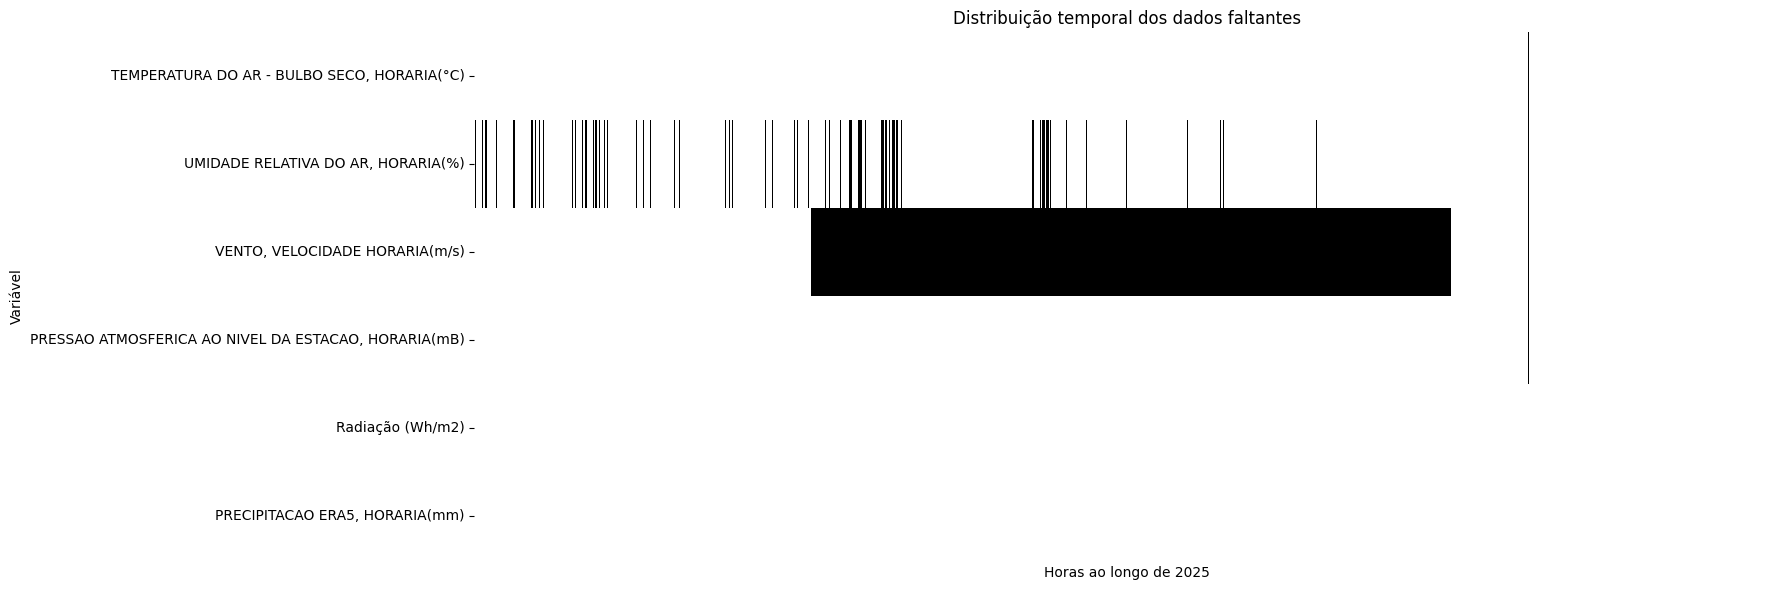

In [ ]:
missing_mask = df.drop(
    columns=['data_hora_utc', 'mes', 'n_missing'],
    errors='ignore'
).isna()

plt.figure(figsize=(18, 6))

sns.heatmap(
    missing_mask.T,
    cmap=["white", "black"],
    cbar=False,
    yticklabels=True,
    xticklabels=False
)

plt.title("Distribuição temporal dos dados faltantes")
plt.xlabel("Horas ao longo de 2025")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()

Ajuste realizada em Umidade, correção dos 505 valores que estavam fora do período Outubro-Dezembor, foi utilizado o IDW entre Valparaíso e P.Prudente, e para uma unica linha onde em todas as 3 estações o valor era nulo, foi utilizado a interpolação temporal linear.      

A velocidade do vento foi inicialmente considerada como variável meteorológica auxiliar. Entretanto, aproximadamente 49% dos registros estavam ausentes, incluindo um extenso bloco contínuo de dados faltantes. A reconstrução da série a partir de estações meteorológicas próximas apresentou desempenho limitado (R² = 0,4474; MAE = 0,98 m/s). Diante da elevada proporção de dados ausentes e da incerteza associada à imputação de grande parte da série, optou-se pela exclusão da variável.        


23/12/2025 09:00 UTC teve uma falha simultânea nas três estações portanto para esse dia foi utilizando interpolação temporal linear.         

Jan Set 10 lacunas de temperatura foram preenchidas pelo IDW previamente validado; uma lacuna isolada, para a qual nenhuma das três estações possuía observação, foi preenchida por interpolação linear entre as horas adjacentes.



### Estatística descritiva

Valores nulos preenchidos, novo dataset gerado com os valores nulos já preenchidos

In [39]:
df_restricao = pd.read_csv('/content/restricao_coff.csv')
df_restricao.head()

,din_instante,val_geracao,val_geracaolimitada,val_disponibilidade,val_geracaoreferencia
0,2025-01-01 00:00:00,0.0,NaN,74.25,0.0
1,2025-01-01 00:30:00,0.0,NaN,74.25,0.0
2,2025-01-01 01:00:00,0.0,NaN,74.25,0.0
3,2025-01-01 01:30:00,0.0,NaN,74.25,0.0
4,2025-01-01 02:00:00,0.0,NaN,74.25,0.0


In [40]:
df_restricao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   din_instante           17520 non-null  object 
 1   val_geracao            17520 non-null  float64
 2   val_geracaolimitada    3188 non-null   float64
 3   val_disponibilidade    17520 non-null  float64
 4   val_geracaoreferencia  17520 non-null  float64
dtypes: float64(4), object(1)
memory usage: 684.5+ KB


In [41]:
df_restricao['din_instante'] = pd.to_datetime(df_restricao['din_instante'])
df_restricao_utc = df_restricao.copy()

In [43]:
df_restricao_utc['din_instante'] = df_restricao_utc['din_instante'].dt.tz_localize('America/Sao_Paulo').dt.tz_convert('UTC')

In [57]:
df_restricao_utc.head()

,data_hora_utc,geracao_mwmed,limite_ons_mwmed,val_disponibilidade,geracao_mwmed_referencia
0,2025-01-01 00:00:00,0.0,NaN,74.25,0.0
1,2025-01-01 00:30:00,0.0,NaN,74.25,0.0
2,2025-01-01 01:00:00,0.0,NaN,74.25,0.0
3,2025-01-01 01:30:00,0.0,NaN,74.25,0.0
4,2025-01-01 02:00:00,0.0,NaN,74.25,0.0


In [45]:
df_restricao_utc['din_instante'] = df_restricao_utc['din_instante'].dt.tz_localize(None)

In [47]:
df_restricao_utc = df_restricao_utc[df_restricao_utc['din_instante'].dt.year != 2026]
novas_linhas = pd.DataFrame({
    'din_instante': pd.date_range(
        '2025-01-01 00:00:00',
        '2025-01-01 02:30:00',
        freq='30min'
    ),
    'val_geracao': 0.0,
    'val_geracaolimitada': np.nan,
    'val_disponibilidade': 74.25,
    'val_geracaoreferencia': 0.0
})

df_restricao_utc = pd.concat([novas_linhas, df_restricao_utc],ignore_index=True)

df_restricao_utc = (
    df_restricao_utc
    .sort_values('din_instante')
    .reset_index(drop=True)
)

In [56]:
df_restricao_utc = df_restricao_utc.rename(columns={
    'din_instante': 'data_hora_utc',
    'val_geracao': 'geracao_mwmed',
    'val_geracaolimitada': 'limite_ons_mwmed',
    'val_geracaoreferencia': 'geracao_mwmed_referencia'
})

In [58]:
df_restricao_utc.to_csv('restricao_coff_utc.csv', index=False)

In [59]:
df_coff_aux = df_restricao_utc.copy()

df_coff_aux['hora'] = df_coff_aux['data_hora_utc'].dt.floor('h')

df_coff_aux['houve_restricao_30min'] = (
    df_coff_aux['limite_ons_mwmed'].notna()
)

In [60]:
df_preenchido = pd.read_csv('/content/df_final_2025_tratado.csv')

In [61]:
df_preenchido.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,26.2,69.0,965.1,0.0,0.000000
1,2025-01-01 01:00:00,25.1,71.0,965.7,0.0,0.000000
2,2025-01-01 02:00:00,25.2,70.0,966.4,0.0,0.016689
3,2025-01-01 03:00:00,25.2,71.0,966.4,0.0,0.055790
4,2025-01-01 04:00:00,24.4,78.0,966.1,0.0,0.017643


In [65]:
df_preenchido['data_hora_utc'] = pd.to_datetime(df_preenchido['data_hora_utc'])

In [66]:
df_preenchido.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 6 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8760 non-null   float64       
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8760 non-null   float64       
 3   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8760 non-null   float64       
 4   Radiação (Wh/m2)                                      8760 non-null   float64       
 5   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 410.8 KB


In [63]:
df_restricao_utc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   data_hora_utc             17520 non-null  datetime64[ns]
 1   geracao_mwmed             17520 non-null  float64       
 2   limite_ons_mwmed          3188 non-null   float64       
 3   val_disponibilidade       17520 non-null  float64       
 4   geracao_mwmed_referencia  17520 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 684.5 KB


In [64]:
df_geracao_utc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   din_instante  8760 non-null   datetime64[ns]
 1   val_geracao   8760 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 137.0 KB


In [67]:
df_geracao_utc = df_geracao_utc.rename(
    columns={
        'din_instante': 'data_hora_utc',
        'val_geracao': 'geracao_mwmed',
    }
)

In [68]:
df_restricao_utc = df_restricao_utc.drop('val_disponibilidade', axis=1)
df_restricao_utc.head()

,data_hora_utc,geracao_mwmed,limite_ons_mwmed,geracao_mwmed_referencia
0,2025-01-01 00:00:00,0.0,NaN,0.0
1,2025-01-01 00:30:00,0.0,NaN,0.0
2,2025-01-01 01:00:00,0.0,NaN,0.0
3,2025-01-01 01:30:00,0.0,NaN,0.0
4,2025-01-01 02:00:00,0.0,NaN,0.0


Se val_geracaolimitada é NaN: alvo = val_geracao     
Horas em que não houve geração o valor vem de Geração por Usina em Base Horária       

Se val_geracaolimitada >= 0: alvo = val_geracaoreferencia      
Nas horas com constrained-off valores de geração substituidos pelo val_geracaoreferencia do dataset de constrained-off

“Quanto a usina realmente gerou?” → geracao_verificada.

“Quanto a usina teria gerado se o ONS não tivesse limitado?” → não existe valor observado. Só pode existir uma estimativa, como geracao_referencia.

In [69]:
print(df_geracao_utc['geracao_mwmed'].isna().sum())
print(df_restricao_utc['geracao_mwmed_referencia'].isna().sum())

0
0


In [70]:
print(df_geracao_utc['data_hora_utc'].duplicated().sum())
print(df_restricao_utc['data_hora_utc'].duplicated().sum())

0
0


In [71]:
print("\nPeríodo geração:")
print(df_geracao_utc['data_hora_utc'].min())
print(df_geracao_utc['data_hora_utc'].max())

print("\nPeríodo meteorologia:")
print(df_preenchido['data_hora_utc'].min())
print(df_preenchido['data_hora_utc'].max())

print("\nPeríodo restricao:")
print(df_restricao_utc['data_hora_utc'].min())
print(df_restricao_utc['data_hora_utc'].max())


Período geração:
2025-01-01 00:00:00
2025-12-31 23:00:00

Período meteorologia:
2025-01-01 00:00:00
2025-12-31 23:00:00

Período restricao:
2025-01-01 00:00:00
2025-12-31 23:30:00


## Juntar os dados de geração e meteorologica.

Serão criados dois dataset para analises


1.   Df 1 -  Remover os horários com restrição, mantendo apenas 7.181 horas
2.   Df 2 - Manter os horários com restrição, as horas com restrição serão substituidas pelo valor de Geração de referência

Regras:
* se nenhuma das duas semi-horas teve limitação → hora sem restrição;
* se pelo menos uma semi-hora teve limite_ons_mwmed != NaN → considerar aquela hora restrita;
* para uma hora restrita, calcular a geração de referência horária como a média das duas referências semi-horárias, já que ambas representam potência média em intervalos de mesma duração.


Se val_geracaolimitada é NaN:
    alvo = val_geracao

Se val_geracaolimitada >= 0:
    alvo = val_geracaoreferencia

1. Preparar o df_restricao para geração horária

In [72]:
df_restricao_utc = df_restricao_utc.sort_values('data_hora_utc').copy()

df_restricao_utc['hora'] = df_restricao_utc['data_hora_utc'].dt.floor('h')

df_restricao_utc['houve_restricao_30min'] = (
    df_restricao_utc['limite_ons_mwmed'].notna()
)

df_restricao_horaria = (
    df_restricao_utc
    .groupby('hora')
    .agg(
        houve_restricao=('houve_restricao_30min', 'any'),
        geracao_referencia_mwmed=('geracao_mwmed_referencia', 'mean')
    )
    .reset_index()
    .rename(columns={'hora': 'data_hora_utc'})
)

df_restricao_horaria.head()

,data_hora_utc,houve_restricao,geracao_referencia_mwmed
0,2025-01-01 00:00:00,False,0.0
1,2025-01-01 01:00:00,False,0.0
2,2025-01-01 02:00:00,False,0.0
3,2025-01-01 03:00:00,False,0.0
4,2025-01-01 04:00:00,False,0.0


2. Juntar Restrição horaria + Geração

In [73]:
df_base = df_geracao_utc.merge(
    df_restricao_horaria,
    on='data_hora_utc',
    how='left',
    validate='one_to_one'
)

df_base.head()

,data_hora_utc,geracao_mwmed,houve_restricao,geracao_referencia_mwmed
0,2025-01-01 00:00:00,0.0,False,0.0
1,2025-01-01 01:00:00,0.0,False,0.0
2,2025-01-01 02:00:00,0.0,False,0.0
3,2025-01-01 03:00:00,0.0,False,0.0
4,2025-01-01 04:00:00,0.0,False,0.0


In [74]:
print(df_base['houve_restricao'].value_counts(dropna=False))

houve_restricao
False    7035
True     1725
Name: count, dtype: int64


### Dataset 1 — somente horas SEM constrained-off
Variável alvo - a geração realmente observada no dataset de geração por usina.   


Meteorologia observada    
        +     
Geração efetivamente observada     
        +     
SEM constrained-off     

In [75]:
df_sem_restricao = (
    df_base.loc[
        df_base['houve_restricao'] == False,
        ['data_hora_utc', 'geracao_mwmed']
    ]
    .merge(
        df_preenchido,
        on='data_hora_utc',
        how='inner',
        validate='one_to_one'
    )
    .sort_values('data_hora_utc')
    .reset_index(drop=True)
)

In [76]:
df_sem_restricao.head()

print('Registros:', len(df_sem_restricao))
print('NaNs:')
print(df_sem_restricao.isna().sum())

Registros: 7035
NaNs:
data_hora_utc                                           0
geracao_mwmed                                           0
TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)             0
UMIDADE RELATIVA DO AR, HORARIA(%)                      0
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)    0
Radiação (Wh/m2)                                        0
PRECIPITACAO ERA5, HORARIA(mm)                          0
dtype: int64


In [77]:
df_sem_restricao.to_csv('df_merge_sem_restricao.csv', index=False)

### Dataset 2 — série corrigida pela geração de referência

In [78]:
df_base['geracao_alvo_mwmed'] = np.where(
    df_base['houve_restricao'],
    df_base['geracao_referencia_mwmed'],
    df_base['geracao_mwmed']
)

df_base['alvo_referencia_ons'] = (
    df_base['houve_restricao']
    .astype(int)
)

df_com_restricao = (
    df_base[
        [
            'data_hora_utc',
            'geracao_alvo_mwmed',
            'alvo_referencia_ons'
        ]
    ]
    .merge(
        df_preenchido,
        on='data_hora_utc',
        how='inner',
        validate='one_to_one'
    )
    .sort_values('data_hora_utc')
    .reset_index(drop=True)
)

df_com_restricao.head()

,data_hora_utc,geracao_alvo_mwmed,alvo_referencia_ons,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,0.0,0,26.2,69.0,965.1,0.0,0.000000
1,2025-01-01 01:00:00,0.0,0,25.1,71.0,965.7,0.0,0.000000
2,2025-01-01 02:00:00,0.0,0,25.2,70.0,966.4,0.0,0.016689
3,2025-01-01 03:00:00,0.0,0,25.2,71.0,966.4,0.0,0.055790
4,2025-01-01 04:00:00,0.0,0,24.4,78.0,966.1,0.0,0.017643


In [79]:
df_com_restricao.to_csv('df_merge_com_restricao.csv', index=False)

In [80]:
print('Registros:', len(df_com_restricao))

print('\nNaNs:')
print(df_com_restricao.isna().sum())

print('\nOrigem do alvo:')
print(df_com_restricao['alvo_referencia_ons'].value_counts())

Registros: 8760

NaNs:
data_hora_utc                                           0
geracao_alvo_mwmed                                      0
alvo_referencia_ons                                     0
TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)             0
UMIDADE RELATIVA DO AR, HORARIA(%)                      0
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)    0
Radiação (Wh/m2)                                        0
PRECIPITACAO ERA5, HORARIA(mm)                          0
dtype: int64

Origem do alvo:
alvo_referencia_ons
0    7035
1    1725
Name: count, dtype: int64


In [81]:
df_validacao = df_base.loc[
    df_base['houve_restricao'],
    [
        'data_hora_utc',
        'geracao_mwmed',
        'geracao_referencia_mwmed',
        'geracao_alvo_mwmed'
    ]
]

df_validacao.head(30)

,data_hora_utc,geracao_mwmed,geracao_referencia_mwmed,geracao_alvo_mwmed
10,2025-01-01 10:00:00,20.398,17.0275,17.0275
11,2025-01-01 11:00:00,16.746,26.8635,26.8635
12,2025-01-01 12:00:00,19.383,36.5205,36.5205
13,2025-01-01 13:00:00,19.197,43.7875,43.7875
14,2025-01-01 14:00:00,23.894,47.2645,47.2645
15,2025-01-01 15:00:00,22.696,40.5645,40.5645
16,2025-01-01 16:00:00,27.393,46.7945,46.7945
17,2025-01-01 17:00:00,6.623,11.9260,11.9260
18,2025-01-01 18:00:00,2.583,1.9735,1.9735
19,2025-01-01 19:00:00,7.664,7.1420,7.1420


In [82]:
df_restricao[
    df_restricao['data_hora_utc'].between(
        '2025-01-01 07:00:00',
        '2025-01-01 07:30:00'
    )
][[
    'data_hora_utc',
    'geracao_mwmed_referencia',
    'limite_ons_mwmed'
]]

,data_hora_utc,geracao_mwmed_referencia,limite_ons_mwmed
14,2025-01-01 07:00:00,13.939,15.834
15,2025-01-01 07:30:00,20.116,18.000
